[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/12-data-annotation-and-rlhf/notebooks/01-annotation-and-kappa.ipynb)

# 01 - Annotation exercise and Cohen's kappa

**Goal:** label a small dataset like a real annotator, then measure how much two annotators agree - first by hand, then with scikit-learn.

**Words you need**
- **Annotation / labelling** - adding the "right answer" (a **label**) to each example.
- **Annotator** - the person who adds labels.
- **Gold question** - an item whose correct label is already known, used to test annotators.
- **Cohen's kappa** - agreement between two annotators after removing the agreement you would get by luck.

Runs on any CPU in seconds. No API keys needed.

## Step 1 - Imports

`pandas` holds tables, `numpy` does maths, `sklearn.metrics` has the ready-made kappa function, `matplotlib` draws charts.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score, confusion_matrix
pd.set_option("display.max_colwidth", 80)
print("ready")

ready


## Step 2 - The task and the guidelines

We are labelling short customer reviews of a phone. Read the **guidelines** (the annotators' rulebook) before looking at the data. Real projects have pages of these; ours fits in one cell.

- **POS** - the reviewer is overall happy with the product.
- **NEG** - the reviewer is overall unhappy with the product.
- **NEU** - no clear opinion about the product (a question, a fact, or about something else such as delivery).
- Edge case - **sarcasm**: label the *meant* opinion. "Great, it died after a day" is NEG.
- Edge case - **mixed**: choose the opinion of the *final verdict* sentence.

In [2]:
reviews = [
    "Battery lasts two full days. Love it.",
    "Screen cracked the first week. Not happy.",
    "Does it come in blue?",
    "Great, it died after one day. Brilliant engineering.",
    "Camera is average but for this price I'm happy.",
    "Delivery was late but that's the courier, not the phone.",
    "Fast, smooth, no complaints.",
    "Speakers are tinny and the case feels cheap.",
    "It is a phone. It makes calls.",
    "Returned it. Overheats when charging.",
    "Best purchase this year!",
    "Good screen, terrible battery, would not buy again.",
    "Arrived on Tuesday.",
    "Oh wonderful, another update that deletes my photos.",
    "Solid value. Recommend to students.",
    "Not bad, not great.",
    "Fingerprint reader fails half the time.",
    "My mum loves it, easy to use.",
    "Box was damaged but phone works perfectly.",
    "Meh.",
]
df = pd.DataFrame({"text": reviews})
df.index.name = "item"
df

,text
item,
0,Battery lasts two full days. Love it.
1,Screen cracked the first week. Not happy.
2,Does it come in blue?
3,"Great, it died after one day. Brilliant engineering."
4,Camera is average but for this price I'm happy.
5,"Delivery was late but that's the courier, not the phone."
6,"Fast, smooth, no complaints."
7,Speakers are tinny and the case feels cheap.
8,It is a phone. It makes calls.


## Step 3 - Two annotators' labels

Here are labels from two (simulated) annotators, A and B. They mostly agree, but they disagree on the hard cases - sarcasm, mixed opinions, and "is this about the product?". That is exactly what happens in real projects.

In [3]:
df["A"] = ["POS","NEG","NEU","NEG","POS","NEU","POS","NEG","NEU","NEG",
           "POS","NEG","NEU","NEG","POS","NEU","NEG","POS","POS","NEU"]
df["B"] = ["POS","NEG","NEU","POS","POS","NEG","POS","NEG","NEU","NEG",
           "POS","NEG","NEU","NEU","POS","NEU","NEG","POS","NEU","NEG"]
df

,text,A,B
item,,,
0,Battery lasts two full days. Love it.,POS,POS
1,Screen cracked the first week. Not happy.,NEG,NEG
2,Does it come in blue?,NEU,NEU
3,"Great, it died after one day. Brilliant engineering.",NEG,POS
4,Camera is average but for this price I'm happy.,POS,POS
5,"Delivery was late but that's the courier, not the phone.",NEU,NEG
6,"Fast, smooth, no complaints.",POS,POS
7,Speakers are tinny and the case feels cheap.,NEG,NEG
8,It is a phone. It makes calls.,NEU,NEU


## Step 4 - Your turn (optional)

Copy annotator A's labels, then change any you disagree with, following the guidelines. Later cells compare *you* with annotator B. If you skip this, the notebook still runs.

In [4]:
my_labels = list(df["A"])      # start from A ...
my_labels[5] = "NEU"           # ... and edit items you disagree with, for example item 5
df["me"] = my_labels
df[["text", "A", "me"]].head(8)

,text,A,me
item,,,
0,Battery lasts two full days. Love it.,POS,POS
1,Screen cracked the first week. Not happy.,NEG,NEG
2,Does it come in blue?,NEU,NEU
3,"Great, it died after one day. Brilliant engineering.",NEG,NEG
4,Camera is average but for this price I'm happy.,POS,POS
5,"Delivery was late but that's the courier, not the phone.",NEU,NEU
6,"Fast, smooth, no complaints.",POS,POS
7,Speakers are tinny and the case feels cheap.,NEG,NEG


## Step 5 - Raw percent agreement

**Observed agreement (p_o)** = the fraction of items where both annotators chose the same label. It is the obvious first number - but section 5.1 of `concepts.md` explains why it can mislead.

In [5]:
agree = df["A"] == df["B"]          # True where the two labels match
p_o = agree.mean()                   # True counts as 1, False as 0, so the mean is a fraction
print(f"A and B agree on {agree.sum()} of {len(df)} items -> p_o = {p_o:.2f}")
print("\nDisagreements:")
df.loc[~agree, ["text", "A", "B"]]

A and B agree on 15 of 20 items -> p_o = 0.75

Disagreements:


,text,A,B
item,,,
3,"Great, it died after one day. Brilliant engineering.",NEG,POS
5,"Delivery was late but that's the courier, not the phone.",NEU,NEG
13,"Oh wonderful, another update that deletes my photos.",NEG,NEU
18,Box was damaged but phone works perfectly.,POS,NEU
19,Meh.,NEU,NEG


## Step 6 - A confusion matrix

A **confusion matrix** is a table that counts every combination of labels: rows are A's label, columns are B's label. The diagonal holds agreements; everything off the diagonal is a disagreement. `pd.crosstab` builds it.

B    POS  NEG  NEU
A                 
POS    6    0    1
NEG    1    5    1
NEU    0    2    4


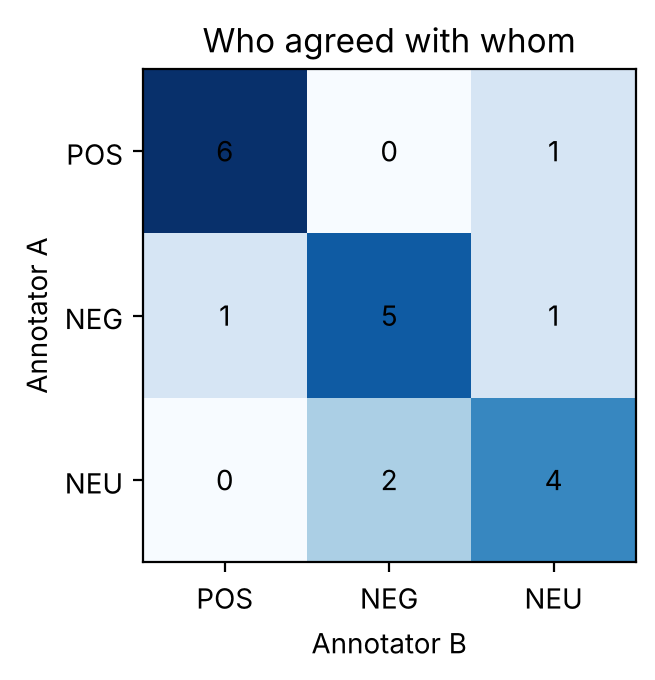

In [6]:
labels = ["POS", "NEG", "NEU"]
cm = pd.crosstab(df["A"], df["B"], rownames=["A"], colnames=["B"]).reindex(index=labels, columns=labels, fill_value=0)
print(cm)
fig, ax = plt.subplots(figsize=(4, 3.5))
ax.imshow(cm.values, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm.values[i, j], ha="center", va="center")
ax.set_xticks(range(3)); ax.set_xticklabels(labels); ax.set_xlabel("Annotator B")
ax.set_yticks(range(3)); ax.set_yticklabels(labels); ax.set_ylabel("Annotator A")
ax.set_title("Who agreed with whom"); plt.tight_layout(); plt.show()

## Step 7 - Cohen's kappa by hand

Formula: `kappa = (p_o - p_e) / (1 - p_e)`.

**Expected agreement (p_e)** is the agreement we would expect if both annotators labelled at random *but with their own habits* (how often each uses each label). For each label: P(A uses it) x P(B uses it). Then add those up.

In [7]:
n = len(df)
p_e = 0.0
for lab in labels:
    pa = (df["A"] == lab).mean()     # how often A uses this label
    pb = (df["B"] == lab).mean()     # how often B uses this label
    print(f"{lab}: A uses it {pa:.2f}, B uses it {pb:.2f}, both by chance {pa*pb:.3f}")
    p_e += pa * pb
kappa_hand = (p_o - p_e) / (1 - p_e)
print(f"\np_o = {p_o:.3f}   p_e = {p_e:.3f}   kappa = {kappa_hand:.3f}")

POS: A uses it 0.35, B uses it 0.35, both by chance 0.122
NEG: A uses it 0.35, B uses it 0.35, both by chance 0.122
NEU: A uses it 0.30, B uses it 0.30, both by chance 0.090

p_o = 0.750   p_e = 0.335   kappa = 0.624


## Step 8 - Write it as a reusable function

A small function means we can reuse the calculation for any two lists of labels.

In [8]:
def cohens_kappa(a, b):
    """Cohen's kappa for two equal-length lists of labels."""
    a, b = np.asarray(a), np.asarray(b)
    cats = np.union1d(a, b)                                   # every label either person used
    p_o = np.mean(a == b)                                     # observed agreement
    p_e = sum(np.mean(a == c) * np.mean(b == c) for c in cats)  # chance agreement
    return (p_o - p_e) / (1 - p_e)

print("our function :", round(cohens_kappa(df["A"], df["B"]), 4))

our function : 0.6241


## Step 9 - Check against scikit-learn

`sklearn.metrics.cohen_kappa_score` is the trusted implementation. If our number matches, our understanding is right.

In [9]:
k_sk = cohen_kappa_score(df["A"], df["B"])
print("scikit-learn :", round(k_sk, 4))
print("you vs B     :", round(cohen_kappa_score(df["me"], df["B"]), 4))
assert abs(k_sk - cohens_kappa(df["A"], df["B"])) < 1e-9

scikit-learn : 0.6241
you vs B     : 0.6241


## Step 10 - The worked example from concepts.md

The 10-item example in `concepts.md` should give 0.52. Checking a hand calculation in code is a good habit.

In [10]:
a = ["POS","POS","NEG","POS","NEG","POS","POS","NEG","POS","POS"]
b = ["POS","NEG","NEG","POS","NEG","POS","POS","POS","POS","POS"]
print(round(cohen_kappa_score(a, b), 2))

0.52


## Step 11 - Why kappa exists: the lazy annotators

Imagine 1,000 emails where about 5% are spam. Two lazy annotators click "ham" (not spam) on almost everything and press "spam" at random 5% of the time. Their percent agreement looks great, but kappa reveals they are not really agreeing about anything.

In [11]:
rng = np.random.default_rng(0)
lazy_a = np.where(rng.random(1000) < 0.05, "spam", "ham")   # random 5% spam clicks
lazy_b = np.where(rng.random(1000) < 0.05, "spam", "ham")
print("lazy percent agreement:", np.mean(lazy_a == lazy_b))
print("lazy kappa            :", round(cohen_kappa_score(lazy_a, lazy_b), 3))

lazy percent agreement: 0.896
lazy kappa            : 0.001


## Step 12 - Gold questions

Five items have a known correct label (decided by an expert). We score each annotator on them. On real platforms, falling below a threshold on gold questions means your work is reviewed or you are removed from the project.

In [12]:
gold = {0: "POS", 3: "NEG", 5: "NEU", 13: "NEG", 18: "POS"}   # item -> correct label
for who in ["A", "B", "me"]:
    correct = sum(df.loc[i, who] == g for i, g in gold.items())
    print(f"{who:>2}: {correct}/{len(gold)} gold questions correct")

 A: 5/5 gold questions correct
 B: 1/5 gold questions correct
me: 5/5 gold questions correct


## Step 13 - Adjudication

When A and B disagree, an **adjudicator** (an expert reviewer) decides. Here we write the decisions with a reason - the reasons become new edge-case examples in the next version of the guidelines.

In [13]:
decisions = {
    3: ("NEG", "sarcasm - 'brilliant' is ironic"),
    5: ("NEU", "complaint is about the courier, not the phone"),
    13: ("NEG", "sarcasm about an update deleting photos"),
    18: ("POS", "final verdict: phone works perfectly"),
    19: ("NEU", "'Meh' is no clear opinion - add to guidelines"),
}
df["final"] = df["A"].where(df["A"] == df["B"])        # keep agreed labels
for i, (lab, why) in decisions.items():
    df.loc[i, "final"] = lab
    print(f"item {i:2d}: {lab}  because {why}")
print("\nAll items labelled:", df["final"].notna().all())

item  3: NEG  because sarcasm - 'brilliant' is ironic
item  5: NEU  because complaint is about the courier, not the phone
item 13: NEG  because sarcasm about an update deleting photos
item 18: POS  because final verdict: phone works perfectly
item 19: NEU  because 'Meh' is no clear opinion - add to guidelines

All items labelled: True


## Step 14 - Weighted kappa for ordered scores (bonus)

When labels have an order (ratings 1-5), a 4 vs 5 disagreement is smaller than 1 vs 5. **Weighted kappa** gives partial credit. scikit-learn supports it with `weights="linear"` or `"quadratic"`.

In [14]:
r1 = [5, 4, 4, 2, 1, 3, 5, 4, 2, 3]
r2 = [4, 4, 5, 2, 2, 3, 5, 3, 1, 3]
print("plain kappa    :", round(cohen_kappa_score(r1, r2), 3))
print("linear weights :", round(cohen_kappa_score(r1, r2, weights="linear"), 3))
print("quadratic      :", round(cohen_kappa_score(r1, r2, weights="quadratic"), 3))

plain kappa    : 0.367
linear weights : 0.648
quadratic      : 0.843


## What you learned

- Percent agreement ignores luck; Cohen's kappa = (p_o - p_e) / (1 - p_e) removes it.
- Disagreements cluster on edge cases - they tell you how to improve the guidelines.
- Gold questions measure each annotator; adjudication produces final labels.
- Next: `02-reward-model.ipynb` uses *preference* labels to train a model.